<a href="https://colab.research.google.com/github/ahchu2525/capstone-hosp/blob/main/hotel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Booking Cancellations - Capstone Notebook

(Prepared by Kelvin Chu)

**Problem statement:** Hotels lose revenue when guests cancel their bookings. Hotel managers need to know when and why guests cancel and how much revenue is at risk.

## Research objectives
1. Measure booking volume and cancellation rate by hotel, month and season.
2. Compare average daily rate and length of stay between the City Hotel and the Resort Hotel across the year.
3. Identify the booking factors linked to higher cancellation rates. These include lead time, deposit type, market segment, distribution channel and customer type.
4. Examine how guest profile and history relate to cancellations. These include repeat guests, previous cancellations, special requests and country of origin.
5. Estimate the revenue lost to cancellations and how far ahead of arrival guests cancel. Find the hotels, segments and months with the largest losses.

Section 7 adds a small predictive extension that goes beyond these objectives.

## 1. Load the data
The 5 CSV files are loaded straight from this GitHub repository.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

bookings = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/Bookings.csv')
hotels = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/Hotels.csv')
segments = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/Market%20Segments.csv')
customer_types = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/Customer%20Types.csv')
status = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/Reservation%20Status.csv')

In [ ]:
print('bookings:', bookings.shape)
print('hotels:', hotels.shape)
print('segments:', segments.shape)
print('customer_types:', customer_types.shape)
print('status:', status.shape)

bookings: (119390, 28)
hotels: (2, 2)
segments: (26, 3)
customer_types: (36, 4)
status: (3, 2)


**Observations - load**
- All 5 files loaded from GitHub with no errors.
- `bookings` is the main table with 119,390 rows and 28 columns.
- The 4 lookup tables are small: 2 hotels, 26 segment and channel pairs, 36 customer type combinations and 3 reservation outcomes.

## 2. Understand the data
Check each table for its structure, missing values, duplicates and odd values. All problems found are listed in the data issues log at the end of this section.

In [ ]:
hotels

,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


In [ ]:
status

,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


In [ ]:
segments

,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct
5,6,Direct,TA/TO
6,7,Groups,Direct
7,8,Groups,Corporate
8,9,Offline TA/TO,Direct
9,10,Groups,TA/TO


In [ ]:
customer_types

,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB
5,6,Transient-Party,No Deposit,BB
6,7,Transient-Party,No Deposit,FB
7,8,Transient-Party,No Deposit,HB
8,9,Group,No Deposit,BB
9,10,Transient-Party,Refundable,BB


**Observations - lookup tables**
- **hotels** has 2 hotels: Resort Hotel and City Hotel.
- **status** has 3 outcomes: Check-Out, Canceled and No-Show.
- **segments** has 26 rows. Each row is 1 pair of market segment and distribution channel. Some rows are labelled `Undefined`.
- **customer_types** has 36 rows. Each row is 1 mix of customer type, deposit type and meal plan. The meal plan has both `SC` and `Undefined`. Both mean no meal package.

In [ ]:
bookings.head()

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


In [ ]:
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

In [ ]:
bookings.describe()

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,0.370416,104.011416,2016.156554,27.165173,15.798241,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,34465.068657,0.472181,3.071532,5.250009,0.505913,0.482918,106.863097,0.707476,13.605138,8.780829,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,0.000000,18.000000,2016.000000,16.000000,8.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,0.000000,69.000000,2016.000000,28.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,1.000000,160.000000,2017.000000,38.000000,23.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119390.000000,2.000000,26.000000,36.000000,3.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


**Observations - structure and summary statistics**
- 28 columns: 21 whole numbers, 4 decimals (`children`, `agent`, `company` and `adr`) and 3 text columns (`arrival_date_month`, `country` and `reservation_status_date`).
- `children` is stored as a decimal only because it has blanks.
- `lead_time` runs from 0 to 737 days with a median of 69 days.
- `adr` runs from -6.38 to 5,400. Both ends look wrong and are checked below.
- `adults` goes up to 55, which points to group bookings.

In [ ]:
bookings.isnull().sum()

,0
Booking_ID,0
Hotel_ID,0
Market_Segment_ID,0
Customer_Type_ID,0
Reservation_ID,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0


In [ ]:
print('Duplicate rows:', bookings.duplicated().sum())
print('Duplicate rows ignoring Booking_ID:', bookings.drop(columns='Booking_ID').duplicated().sum())

Duplicate rows: 0
Duplicate rows ignoring Booking_ID: 33010


In [ ]:
print('Bookings with no guests:', ((bookings['adults'] + bookings['children'] + bookings['babies']) == 0).sum())
print('Bookings with 0 nights:', ((bookings['stays_in_weekend_nights'] + bookings['stays_in_week_nights']) == 0).sum())
print('ADR below 0:', (bookings['adr'] < 0).sum())
print('ADR equal to 0:', (bookings['adr'] == 0).sum())
print('Top 3 ADR values:', bookings['adr'].sort_values(ascending=False).head(3).tolist())

Bookings with no guests: 180
Bookings with 0 nights: 715
ADR below 0: 1
ADR equal to 0: 1959
Top 3 ADR values: [5400.0, 510.0, 508.0]


**Observations - missing values, duplicates and odd values**
- 4 columns have blanks. `company` is 94% blank so it is too empty to use.
- Every booking has its own ID. However 33,010 rows match another booking in every other column. These are likely several rooms in 1 group booking.
- 180 bookings have no guests and 1 has a negative ADR. These are not valid bookings.
- The top ADR of 5,400 is more than 10 times the next highest (510). It is likely a typing error.
- 1,959 bookings have an ADR of 0. Many are likely free stays so they are kept.

In [ ]:
bookings['is_canceled'].value_counts()

,count
is_canceled,
0,75166
1,44224


In [ ]:
bookings['arrival_date_year'].value_counts().sort_index()

,count
arrival_date_year,
2015,21996
2016,56707
2017,40687


In [ ]:
bookings['country'].value_counts().head(10)

,count
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
ITA,3766
IRL,3375
BEL,2342
BRA,2224


In [ ]:
print(bookings['Hotel_ID'].isin(hotels['Hotel_ID']).all())
print(bookings['Market_Segment_ID'].isin(segments['Market_Segment_ID']).all())
print(bookings['Customer_Type_ID'].isin(customer_types['Customer_Type_ID']).all())
print(bookings['Reservation_ID'].isin(status['Reservation_ID']).all())

True
True
True
True


**Observations - categories and keys**
- 44,224 of 119,390 bookings (37.0%) were cancelled.
- 2016 has the most bookings (56,707). 2015 and 2017 are part years: July to December 2015 and January to August 2017.
- Portugal (PRT) is the largest market with 48,590 bookings. The UK (GBR) follows with 12,129 and France (FRA) with 10,415.
- Every ID in `bookings` has a match in its lookup table, so no bookings will be lost in the join.

### Data issues summary

| No. | Issue | Rows | Plan |
| --- | --- | --- | --- |
| 1 | `children` is blank | 4 | Fill with 0 |
| 2 | `country` is blank | 488 | Fill with `Unknown` |
| 3 | `agent` is blank | 16,340 | Means no agent. Fill with 0 and add a `has_agent` column |
| 4 | `company` is blank | 112,593 | Too empty to use. Add a `has_company` column then drop `company` |
| 5 | No adults, children or babies | 180 | Remove. A booking with no guests is not valid |
| 6 | `adr` below 0 | 1 | Remove |
| 7 | `adr` of 5,400 (next highest is 510) | 1 | Remove as a typing error |
| 8 | `adr` of 0 | 1,959 | Keep. Many are free stays |
| 9 | 0 nights booked | 715 | Keep. These add 0 revenue |
| 10 | Meal plan has both `SC` and `Undefined` | Count after join | Merge into `No meal` |
| 11 | Segment or channel is `Undefined` | Count after join | Remove. Too few to analyse |
| 12 | Arrival date split over 3 columns with month as text | All | Build 1 `arrival_date` column |
| 13 | Rows identical except `Booking_ID` | 33,010 | Keep for the dashboard. Likely several rooms in 1 group booking. Remove before modelling |
| 14 | `reservation_status` gives away the answer to `is_canceled` | All | Use in the dashboard only. Never use in the model |

## 3. Clean the data
The 4 lookup tables are joined onto bookings. Then the issues in the data issues summary are fixed. All cleaning is done on a copy called `df_cleaned`. The joined table `df` is not changed.

In [ ]:
df = bookings.merge(hotels, on='Hotel_ID', how='left')
df = df.merge(segments, on='Market_Segment_ID', how='left')
df = df.merge(customer_types, on='Customer_Type_ID', how='left')
df = df.merge(status, on='Reservation_ID', how='left')

df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['room_revenue'] = df['adr'] * df['total_nights']

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

print(df.shape)

(119390, 37)


### 3.1 Count the label issues
Rows 10 and 11 of the data issues summary needed the join to count them.

In [ ]:
df['meal'].value_counts()

,count
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798


In [ ]:
df['market_segment'].value_counts()

,count
market_segment,
Online TA,56477
Offline TA/TO,24219
Groups,19811
Direct,12606
Corporate,5295
Complementary,743
Aviation,237
Undefined,2


In [ ]:
df['distribution_channel'].value_counts()

,count
distribution_channel,
TA/TO,97870
Direct,14645
Corporate,6677
GDS,193
Undefined,5


**Counts for rows 10 and 11:**
- Row 10: 11,819 bookings have meal `SC` (10,650) or `Undefined` (1,169).
- Row 11: 2 bookings have an `Undefined` segment and 5 have an `Undefined` channel. The 2 are among the 5 so only 5 bookings are affected.

### 3.2 Make a copy

In [ ]:
df_cleaned = df.copy()

### 3.3 Fill missing values (issues 1 to 4)
`has_agent` and `has_company` are created first. They record which bookings had an agent or company before the blanks are filled.

In [ ]:
df_cleaned['children'] = df_cleaned['children'].fillna(0).astype(int)
df_cleaned['country'] = df_cleaned['country'].fillna('Unknown')
df_cleaned['has_agent'] = df_cleaned['agent'].notnull().astype(int)
df_cleaned['agent'] = df_cleaned['agent'].fillna(0).astype(int)
df_cleaned['has_company'] = df_cleaned['company'].notnull().astype(int)
df_cleaned = df_cleaned.drop(columns=['company'])

df_cleaned.isnull().sum().sum()

np.int64(0)

**Observation:** No missing values remain. `has_agent` and `has_company` keep a record of which bookings had an agent or a company.

### 3.4 Remove invalid rows (issues 5, 6, 7 and 11)

In [ ]:
print('Rows before:', len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned['adults'] + df_cleaned['children'] + df_cleaned['babies']) > 0]
print('After removing bookings with no guests:', len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned['adr'] >= 0) & (df_cleaned['adr'] < 1000)]
print('After removing invalid ADR:', len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned['market_segment'] != 'Undefined') & (df_cleaned['distribution_channel'] != 'Undefined')]
print('After removing Undefined segment or channel:', len(df_cleaned))

Rows before: 119390
After removing bookings with no guests: 119210
After removing invalid ADR: 119208
After removing Undefined segment or channel: 119203


**Observation:** 187 rows were removed: 180 with no guests, 2 with an impossible ADR and 5 with an Undefined segment or channel. This is only 0.2% of bookings, so the results are not affected in a meaningful way.

### 3.5 Fix meal labels (issue 10)

In [ ]:
df_cleaned['meal'] = df_cleaned['meal'].replace({'SC': 'No meal', 'Undefined': 'No meal'})
df_cleaned['meal'].value_counts()

,count
meal,
BB,92230
HB,14457
No meal,11718
FB,798


**Observation:** `No meal` now holds 11,718 bookings. BB (bed and breakfast) is the most common meal plan with 92,230 bookings. HB is half board and FB is full board.

### 3.6 Build dates (issue 12)
The arrival date is split over 3 columns with the month as text. It is combined into 1 date column. `reservation_status_date` is changed from text to a date.

In [ ]:
df_cleaned['arrival_date'] = pd.to_datetime(
    df_cleaned['arrival_date_year'].astype(str) + '-' +
    df_cleaned['arrival_date_month'] + '-' +
    df_cleaned['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')

df_cleaned['reservation_status_date'] = pd.to_datetime(df_cleaned['reservation_status_date'])

print('First arrival:', df_cleaned['arrival_date'].min())
print('Last arrival:', df_cleaned['arrival_date'].max())

First arrival: 2015-07-01 00:00:00
Last arrival: 2017-08-31 00:00:00


**Observation:** Arrivals run from 1 July 2015 to 31 August 2017. This matches the 26 months in the data.

### 3.7 Create new columns
`total_nights` and `room_revenue` were created when the tables were joined at the start of this section. `lead_time_band` and `had_previous_cancel` are created in section 4. The columns below are added for the Power BI dashboard.

| New column | How it is made |
| --- | --- |
| `total_guests` | Adults + children + babies |
| `arrival_month_num` | Month number from `arrival_date`. Used to sort months in order |
| `arrival_weekday` | Day of the week from `arrival_date` |
| `season` | Winter, Spring, Summer or Autumn from the month |
| `has_children` | 1 if the booking has children or babies |
| `is_domestic` | 1 if the guest is from Portugal |
| `cancel_days_before_arrival` | Arrival date minus cancel date. Cancelled bookings only |

In [ ]:
df_cleaned['total_guests'] = df_cleaned['adults'] + df_cleaned['children'] + df_cleaned['babies']
df_cleaned['arrival_month_num'] = df_cleaned['arrival_date'].dt.month
df_cleaned['arrival_weekday'] = df_cleaned['arrival_date'].dt.day_name()

season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df_cleaned['season'] = df_cleaned['arrival_month_num'].map(season_map)

df_cleaned['has_children'] = ((df_cleaned['children'] + df_cleaned['babies']) > 0).astype(int)
df_cleaned['is_domestic'] = (df_cleaned['country'] == 'PRT').astype(int)

df_cleaned['cancel_days_before_arrival'] = (df_cleaned['arrival_date'] - df_cleaned['reservation_status_date']).dt.days
df_cleaned.loc[df_cleaned['reservation_status'] != 'Canceled', 'cancel_days_before_arrival'] = np.nan

df_cleaned['season'].value_counts()

,count
season,
Summer,37429
Spring,32624
Autumn,28418
Winter,20732


**Observation:** Summer has the most arrivals (37,429) and Winter the fewest (20,732).

### 3.8 Drop columns no longer needed
The 4 ID columns were only needed for the join. `arrival_date_day_of_month` is now part of `arrival_date`. `arrival_date_week_number` does not match the calendar for many rows so it is not used.

In [ ]:
df_cleaned = df_cleaned.drop(columns=['arrival_date_week_number', 'arrival_date_day_of_month',
                                      'Hotel_ID', 'Market_Segment_ID', 'Customer_Type_ID', 'Reservation_ID'])

### 3.9 Final checks

In [ ]:
print(df_cleaned.shape)
print(df_cleaned.isnull().sum()[df_cleaned.isnull().sum() > 0])
print('Cancellation rate:', round(df_cleaned['is_canceled'].mean() * 100, 1), '%')

(119203, 40)
cancel_days_before_arrival    76215
dtype: int64
Cancellation rate: 37.1 %


**Observation:** The clean data has 119,203 rows and 40 columns. The only blanks are 76,215 stays and no-shows, which have no cancellation date by design. The cancellation rate is 37.1%.

### 3.10 Summary of cleaning
- Filled blanks in `children`, `country` and `agent`. Dropped `company` after recording `has_company`.
- Removed 187 invalid rows: 180 with no guests, 2 with an impossible ADR and 5 with an Undefined segment or channel.
- Merged meal codes `SC` and `Undefined` into `No meal`.
- Built `arrival_date` and converted `reservation_status_date` to a date.
- Added 10 new columns for the dashboard.
- Dropped 6 columns no longer needed.
- Final data: 119,203 rows and 40 columns. Cancellation rate 37.1%.

## 4. Exploratory data analysis
Each part below answers 1 research objective with charts and a written finding. This is done on the clean data `df_cleaned` from section 3.

In [ ]:
stayed = df_cleaned[df_cleaned['is_canceled'] == 0]
cancelled = df_cleaned[df_cleaned['is_canceled'] == 1]

### 4.1 Overall cancellations

In [ ]:
print('Overall cancellation rate:', round(df_cleaned['is_canceled'].mean() * 100, 1), '%')
df_cleaned['reservation_status'].value_counts()

Overall cancellation rate: 37.1 %


,count
reservation_status,
Check-Out,75009
Canceled,42988
No-Show,1206


hotel
City Hotel      41.8
Resort Hotel    27.8
Name: is_canceled, dtype: float64


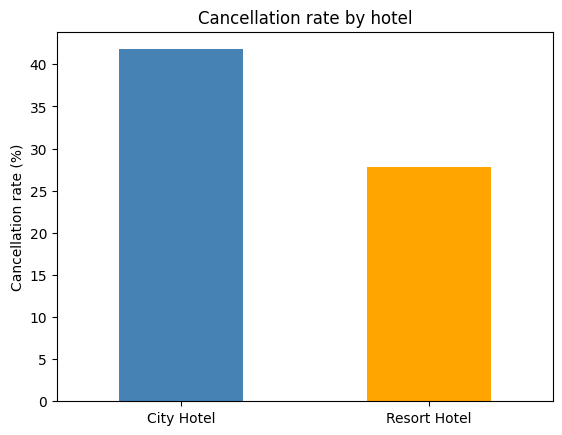

In [ ]:
rate = df_cleaned.groupby('hotel')['is_canceled'].mean() * 100
print(rate.round(1))

rate.plot(kind='bar', color=['steelblue', 'orange'])
plt.title('Cancellation rate by hotel')
plt.ylabel('Cancellation rate (%)')
plt.xlabel('')
plt.xticks(rotation=0)
plt.show()

**Finding:** 37% of all bookings were cancelled or did not show up. The City Hotel cancels far more often (41.8%) than the Resort Hotel (27.8%).

### 4.2 Objective 1 - Booking volume and cancellation rate by month

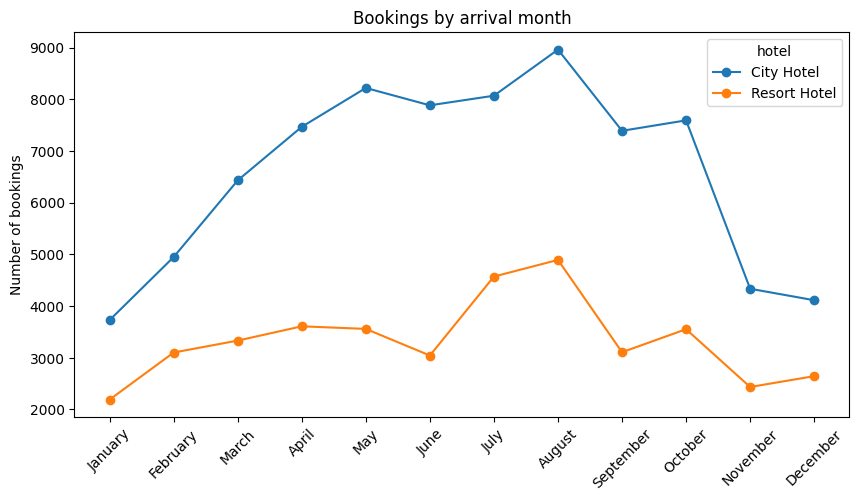

In [ ]:
monthly = df_cleaned.groupby(['arrival_date_month', 'hotel'])['is_canceled'].count().unstack()
monthly = monthly.reindex(month_order)

monthly.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Bookings by arrival month')
plt.ylabel('Number of bookings')
plt.xlabel('')
plt.xticks(range(12), month_order, rotation=45)
plt.show()

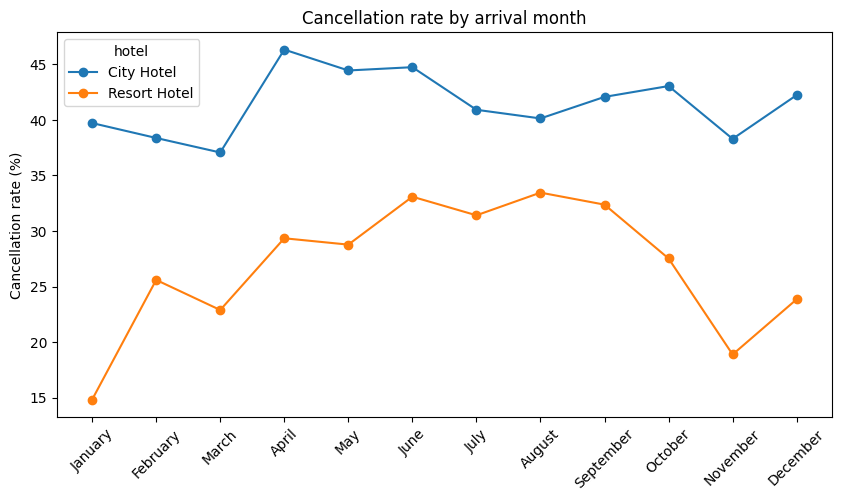

In [ ]:
monthly_rate = df_cleaned.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean().unstack() * 100
monthly_rate = monthly_rate.reindex(month_order)

monthly_rate.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Cancellation rate by arrival month')
plt.ylabel('Cancellation rate (%)')
plt.xlabel('')
plt.xticks(range(12), month_order, rotation=45)
plt.show()

In [ ]:
df_cleaned.groupby('arrival_date_year')['is_canceled'].agg(['count', 'mean'])

,count,mean
arrival_date_year,,
2015,21962,0.370504
2016,56622,0.358924
2017,40619,0.387356


**Finding:** Both hotels are busiest in summer. The Resort Hotel's cancellation rate more than doubles from January to August. The City Hotel stays around 40% all year.

**Note:** The data runs from July 2015 to August 2017. July and August appear in 3 years while other months appear in 2. Month totals for July and August are higher partly because of this. Rates and averages are not affected.

### 4.3 Objective 2 - Price (ADR) and length of stay
ADR is the average daily rate: the average price paid per room per night. Only bookings that went ahead are used.

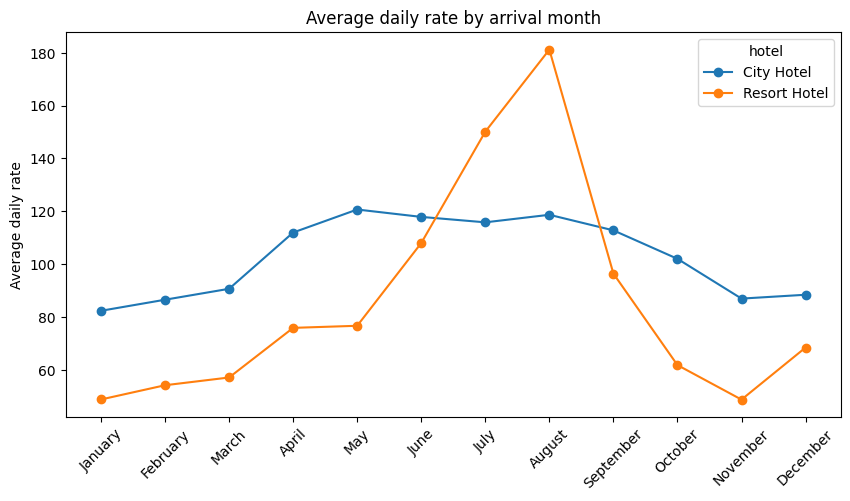

In [ ]:
adr_month = stayed.groupby(['arrival_date_month', 'hotel'])['adr'].mean().unstack()
adr_month = adr_month.reindex(month_order)

adr_month.plot(kind='line', marker='o', figsize=(10, 5))
plt.title('Average daily rate by arrival month')
plt.ylabel('Average daily rate')
plt.xlabel('')
plt.xticks(range(12), month_order, rotation=45)
plt.show()

hotel
City Hotel      2.92
Resort Hotel    4.14
Name: total_nights, dtype: float64


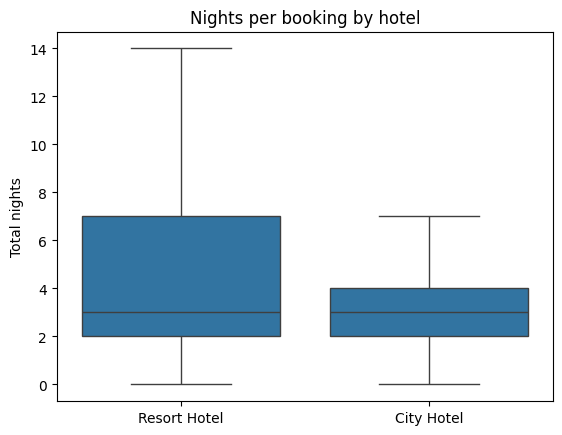

In [ ]:
print(stayed.groupby('hotel')['total_nights'].mean().round(2))

sns.boxplot(data=stayed, x='hotel', y='total_nights', showfliers=False)
plt.title('Nights per booking by hotel')
plt.ylabel('Total nights')
plt.xlabel('')
plt.show()

**Finding:** Resort Hotel prices are highly seasonal and almost 4 times higher in August than in January. City Hotel prices are steadier. Resort guests stay over 1 night longer on average.

### 4.4 Objective 3 - Booking factors
The red dashed line on each chart is the overall cancellation rate of 37%.

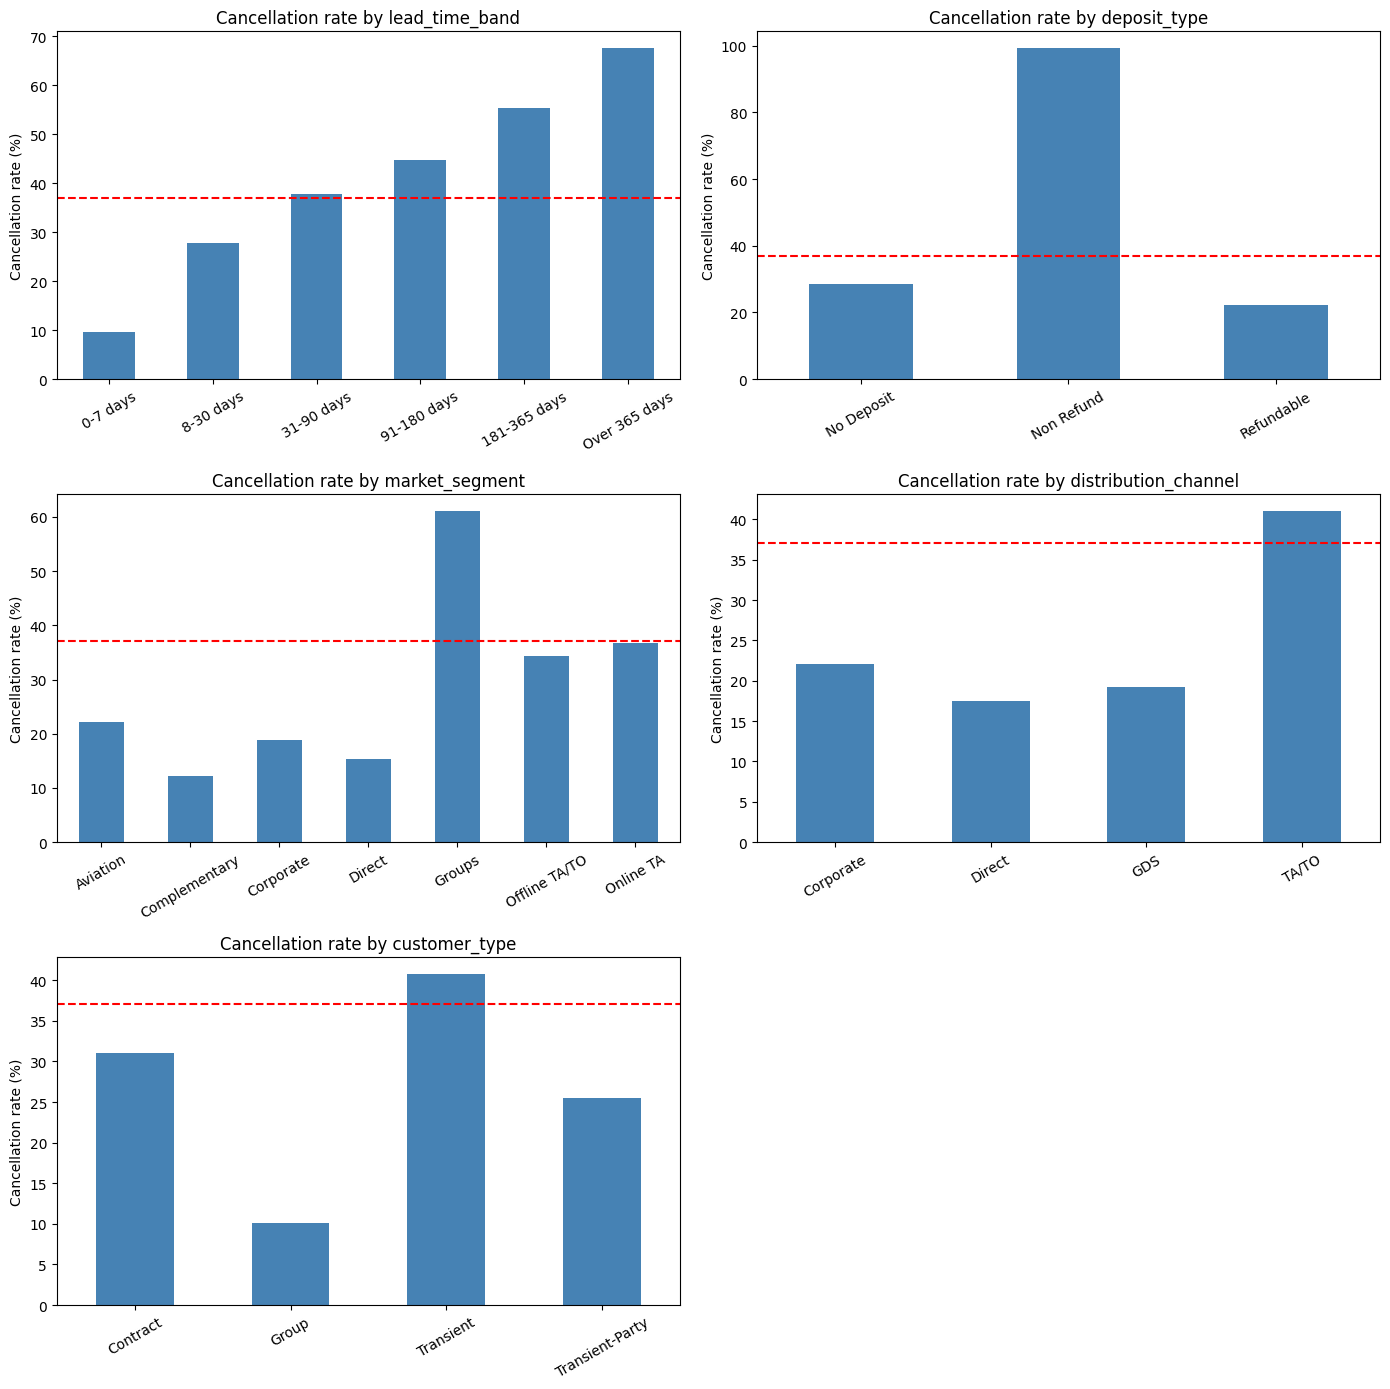

In [ ]:
df_cleaned['lead_time_band'] = pd.cut(df_cleaned['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                              labels=['0-7 days', '8-30 days', '31-90 days',
                                      '91-180 days', '181-365 days', 'Over 365 days'])

factors = ['lead_time_band', 'deposit_type', 'market_segment', 'distribution_channel', 'customer_type']
overall = df_cleaned['is_canceled'].mean() * 100

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(factors):
    rate = df_cleaned.groupby(col, observed=True)['is_canceled'].mean() * 100
    rate.plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].axhline(overall, color='red', linestyle='--')
    axes[i].set_title('Cancellation rate by ' + col)
    axes[i].set_ylabel('Cancellation rate (%)')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)

axes[5].axis('off')
plt.tight_layout()
plt.show()

**Finding:**
- The further ahead a booking is made the more likely it is to cancel. Bookings made over a year ahead cancel 7 times more often than those made within a week.
- 99.4% of Non Refund bookings cancel. This is unexpected and needs a closer look.
- Groups and travel agent bookings cancel most. Direct and corporate bookings cancel least.
- The `Undefined` segment and channel had only 2 and 5 bookings so they were removed in section 3.

### 4.5 Objective 4 - Guest profile and history

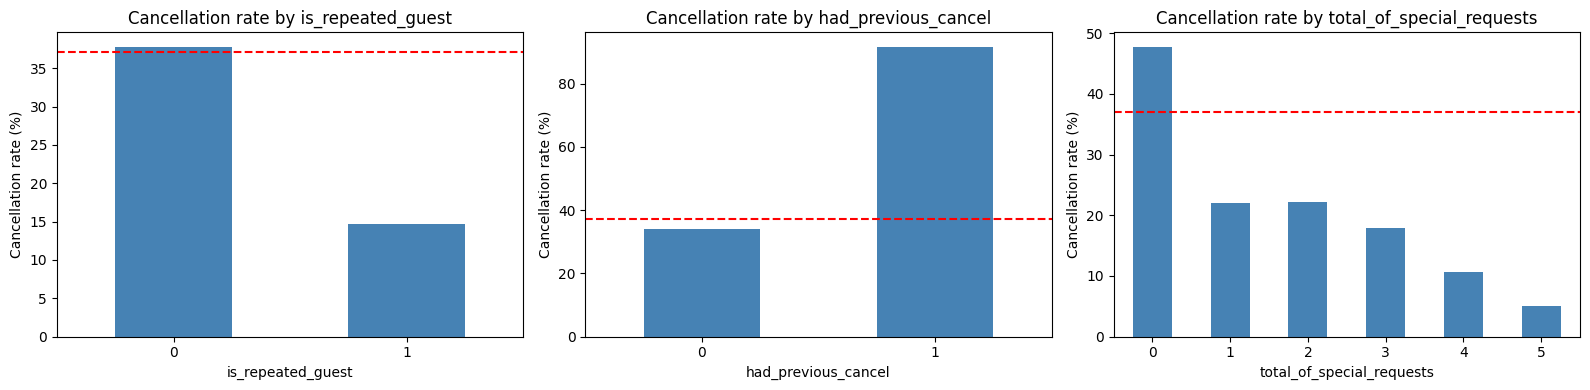

In [ ]:
df_cleaned['had_previous_cancel'] = (df_cleaned['previous_cancellations'] > 0).astype(int)
guest_factors = ['is_repeated_guest', 'had_previous_cancel', 'total_of_special_requests']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(guest_factors):
    rate = df_cleaned.groupby(col)['is_canceled'].mean() * 100
    rate.plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].axhline(overall, color='red', linestyle='--')
    axes[i].set_title('Cancellation rate by ' + col)
    axes[i].set_ylabel('Cancellation rate (%)')
    axes[i].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

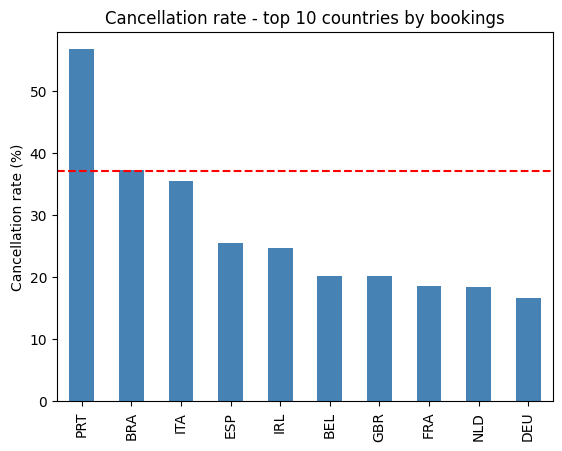

In [ ]:
top10 = df_cleaned['country'].value_counts().head(10).index
country_rate = df_cleaned[df_cleaned['country'].isin(top10)].groupby('country')['is_canceled'].mean() * 100

country_rate.sort_values(ascending=False).plot(kind='bar', color='steelblue')
plt.axhline(overall, color='red', linestyle='--')
plt.title('Cancellation rate - top 10 countries by bookings')
plt.ylabel('Cancellation rate (%)')
plt.xlabel('')
plt.show()

**Finding:**
- Repeat guests cancel much less (14.7%) than new guests (37.8%).
- Guests who cancelled before cancel again 91.7% of the time.
- Guests who make special requests cancel half as often. A request shows the guest plans to come.
- Local guests from Portugal cancel 56.7% of the time. Most foreign guests cancel under 25%.

### 4.6 Objective 5 - Revenue lost
Room revenue is ADR x total nights. How far ahead guests cancel is shown in 4.7.

In [ ]:
print('Revenue earned (millions):', round(stayed['room_revenue'].sum() / 1000000, 2))
print('Revenue lost (millions):', round(cancelled['room_revenue'].sum() / 1000000, 2))
print(cancelled.groupby('hotel')['room_revenue'].sum() / 1000000)

Revenue earned (millions): 25.99
Revenue lost (millions): 16.72
hotel
City Hotel      10.879052
Resort Hotel     5.842177
Name: room_revenue, dtype: float64


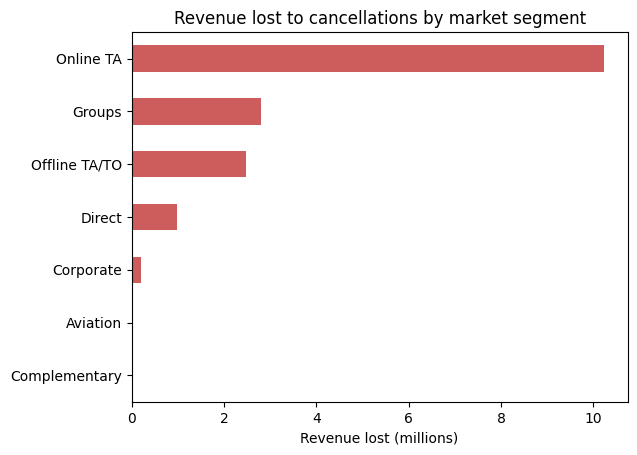

In [ ]:
lost_segment = cancelled.groupby('market_segment')['room_revenue'].sum() / 1000000

lost_segment.sort_values().plot(kind='barh', color='indianred')
plt.title('Revenue lost to cancellations by market segment')
plt.xlabel('Revenue lost (millions)')
plt.ylabel('')
plt.show()

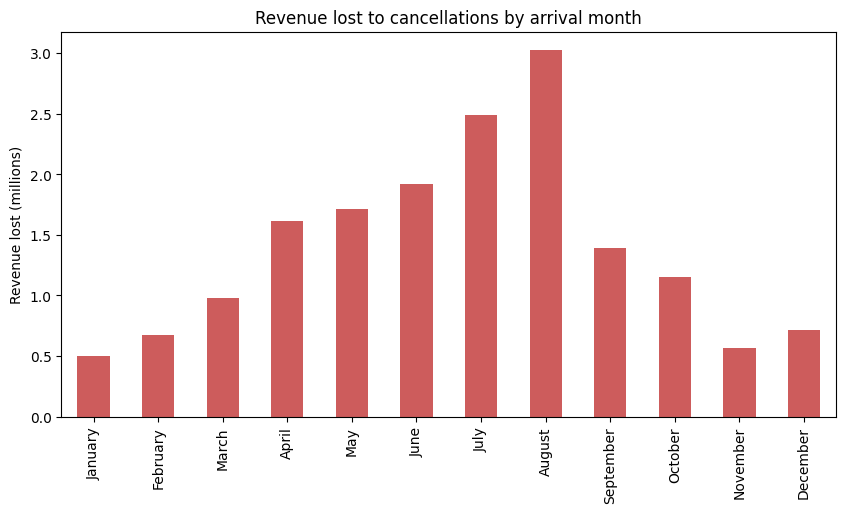

In [ ]:
lost_month = cancelled.groupby('arrival_date_month')['room_revenue'].sum() / 1000000
lost_month = lost_month.reindex(month_order)

lost_month.plot(kind='bar', color='indianred', figsize=(10, 5))
plt.title('Revenue lost to cancellations by arrival month')
plt.ylabel('Revenue lost (millions)')
plt.xlabel('')
plt.show()

**Finding:** Cancelled bookings were worth 16.7 million against 26.0 million earned. Online travel agent bookings make up 10.2 million of the loss. Summer months lose the most because prices and bookings are both highest.

**Note:** This is the room value of cancelled bookings. Some rooms were resold and some deposits were kept so the real loss is lower.

### 4.7 Objective 5 (continued) - How far ahead guests cancel
This part of objective 5 uses the dates built in 3.6.

Median days before arrival: 56.0
Cancelled within 7 days of arrival (%): 11.9
Cancelled within 30 days of arrival (%): 33.7
hotel
City Hotel      58.0
Resort Hotel    51.0
Name: cancel_days_before_arrival, dtype: float64


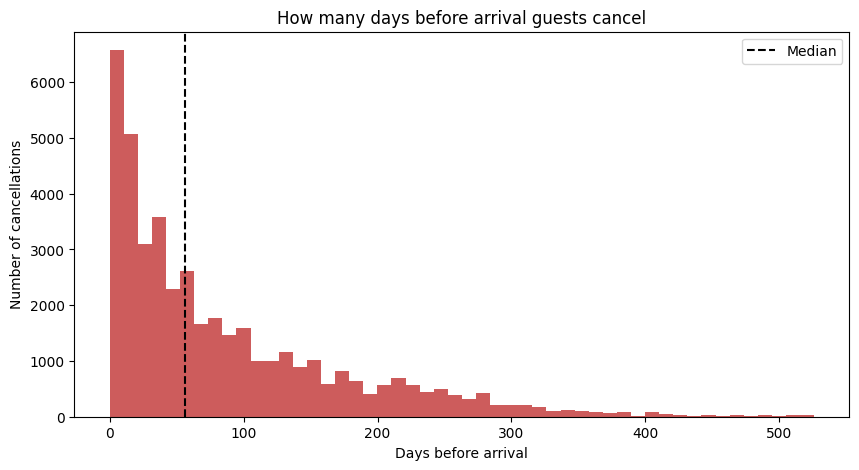

In [ ]:
cancel_days = df_cleaned['cancel_days_before_arrival'].dropna()

print('Median days before arrival:', cancel_days.median())
print('Cancelled within 7 days of arrival (%):', round((cancel_days <= 7).mean() * 100, 1))
print('Cancelled within 30 days of arrival (%):', round((cancel_days <= 30).mean() * 100, 1))
print(df_cleaned.groupby('hotel')['cancel_days_before_arrival'].median())

plt.figure(figsize=(10, 5))
plt.hist(cancel_days, bins=50, color='indianred')
plt.axvline(cancel_days.median(), color='black', linestyle='--', label='Median')
plt.title('How many days before arrival guests cancel')
plt.xlabel('Days before arrival')
plt.ylabel('Number of cancellations')
plt.legend()
plt.show()

**Finding:** Half of all cancellations happen more than 56 days before arrival. This gives the hotel time to resell those rooms. However 1 in 3 cancellations come within 30 days of arrival and 11.9% within the last week. These late cancellations are the hardest to resell. They make up 31.7% of the room value of cancelled bookings.

### 4.8 Correlation between numeric columns

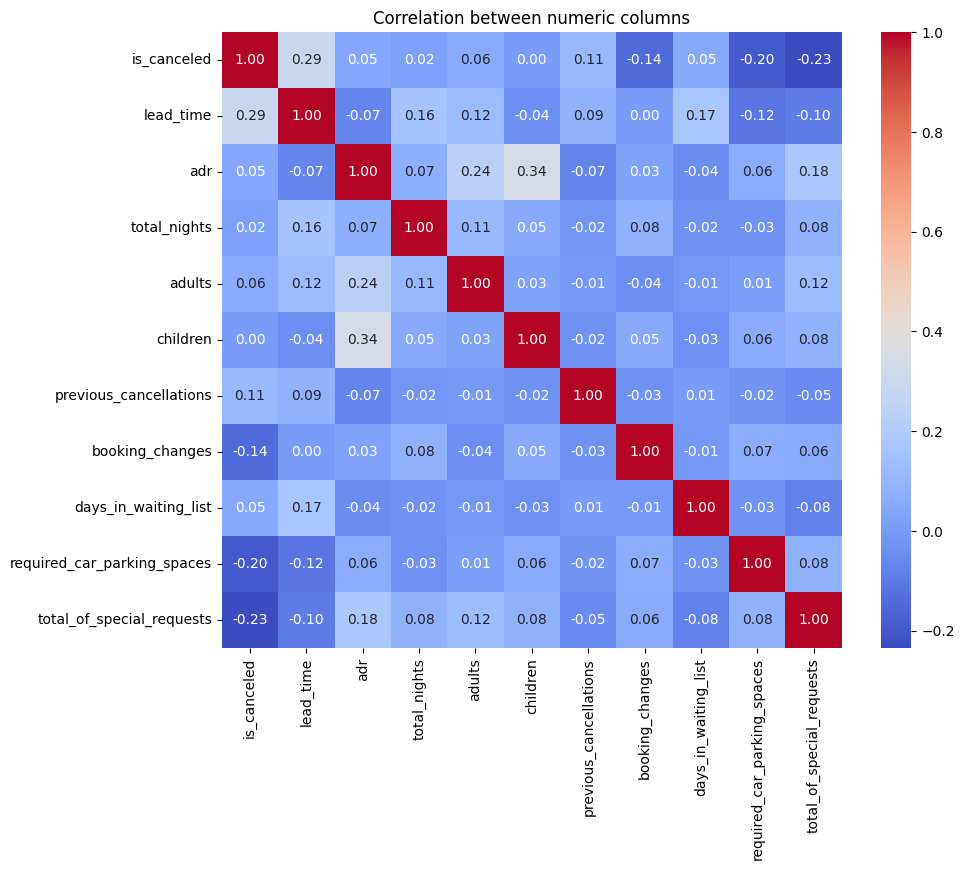

In [ ]:
cols = ['is_canceled', 'lead_time', 'adr', 'total_nights', 'adults', 'children',
        'previous_cancellations', 'booking_changes', 'days_in_waiting_list',
        'required_car_parking_spaces', 'total_of_special_requests']

plt.figure(figsize=(10, 8))
sns.heatmap(df_cleaned[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric columns')
plt.show()

**Finding:** Lead time has the strongest positive link with cancellation. Special requests and parking requests have the strongest negative links. All links are moderate or weak so no single number explains cancellations on its own.

### 4.9 Summary of findings
1. 37% of bookings were cancelled. The City Hotel cancels more than the Resort Hotel.
2. Both hotels peak in summer. Resort Hotel prices are nearly 4 times higher in August than in January.
3. Long lead times, Non Refund deposits, group bookings and travel agent bookings cancel most.
4. Repeat guests and guests with special requests cancel least. Guests who cancelled before usually cancel again.
5. Cancelled bookings were worth 16.7 million. Online travel agents account for 10.2 million.

## 5. Prepare the data for Power BI
The clean data is saved as `hotel_clean.csv` and uploaded to this repository. Power BI reads it straight from GitHub. It has the 40 columns from section 3 plus `lead_time_band` and `had_previous_cancel` from section 4.

In [ ]:
df_cleaned.to_csv('hotel_clean.csv', index=False)
print('Saved hotel_clean.csv with', df_cleaned.shape[0], 'rows and', df_cleaned.shape[1], 'columns')

Saved hotel_clean.csv with 119203 rows and 42 columns


In [ ]:
from google.colab import files
files.download('hotel_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
check = pd.read_csv('https://raw.githubusercontent.com/ahchu2525/capstone-hosp/main/hotel_clean.csv')
print(check.shape)

(119203, 42)


**Clean file:** `hotel_clean.csv` has 119,203 rows and 42 columns. Power BI connects to it through its GitHub raw link so the dashboard can be refreshed when the file is updated.

## 6. Conclusion and recommendations
This section answers each research objective, turns the findings into actions for hotel managers and states the limits of the data.

### 6.1 Answers to the research objectives

| Objective | Answer |
| --- | --- |
| 1. Booking volume and cancellation rate | 37.1% of bookings were cancelled or did not show up. The City Hotel cancels 41.8% of bookings and the Resort Hotel 27.8%. Both hotels are busiest in summer. The Resort Hotel's cancellation rate more than doubles from 14.8% in January to 33.4% in August |
| 2. Price and length of stay | The Resort Hotel's average daily rate rises from about 49 in January to 181 in August. City Hotel prices are steadier at 82 to 121. Resort guests stay 4.14 nights on average compared with 2.92 at the City Hotel |
| 3. Booking factors | Cancellation rises with lead time from 9.6% (within 7 days) to 67.7% (over a year ahead). 99.4% of Non Refund bookings cancel. Groups cancel most (61.1%) and Direct bookings least (15.4%) |
| 4. Guest profile and history | Repeat guests cancel 14.7% of the time compared with 37.8% for new guests. Guests who cancelled before cancel again 91.7% of the time. Guests with no special requests cancel 47.8% of the time compared with 22.0% with 1 request. Guests from Portugal cancel 56.7% of the time |
| 5. Revenue lost | Cancelled bookings were worth 16.7 million against 26.0 million earned. This is 39.2% of all booked room revenue. Online travel agents account for 10.2 million of the loss. August loses the most at 3.0 million. Half of all cancellations happen more than 56 days before arrival but 11.9% come within the last week |

### 6.2 Recommendations

1. **Ask for a deposit on bookings made far ahead.** Bookings made more than 90 days before arrival cancel 44.7% to 67.7% of the time. A part deposit or a reconfirmation 30 days before arrival would show which of these guests still plan to come.
2. **Agree release dates with groups and tour operators.** Groups cancel 61.1% of the time and 99.4% of Non Refund bookings cancel. Most of these come from groups and offline travel agents. A fixed date to release unsold rooms would let the hotel resell them in time. The way Non Refund bookings are recorded should also be checked.
3. **Grow direct bookings.** Online travel agents account for 10.2 million of the 16.7 million lost. Direct bookings cancel only 15.4% of the time. Offering a benefit for booking direct would shift bookings to the lower-risk channel.
4. **Remind guests 2 weeks before arrival.** 11.9% of cancellations come in the last week, when rooms are hardest to resell. A reminder message 14 days before arrival would bring some of these cancellations forward.
5. **Plan overbooking by hotel and season.** The City Hotel cancels far more often than the Resort Hotel, and the Resort Hotel's rate doubles in summer. Overbooking levels should follow the cancellation rate for each hotel and month instead of 1 fixed level.
6. **Reward repeat guests and invite special requests.** Repeat guests and guests with special requests cancel much less. A simple loyalty offer and a prompt to add room preferences at booking would encourage the behaviour linked to lower cancellation.
7. **Take extra care with guests who cancelled before.** These guests cancel again 91.7% of the time. Asking them for a deposit would protect the hotel from repeat losses.

### 6.3 Limitations

- The data covers only 2 hotels in Portugal from July 2015 to August 2017. Results may differ for other hotels or more recent years.
- The data dictionary does not state the currency for the average daily rate.
- Revenue lost is the room value of cancelled bookings. The data does not show which rooms were resold or which deposits were kept, so the real loss is lower.
- 33,010 bookings are identical except for the booking ID. They were kept as group bookings but this cannot be confirmed.
- The data does not record why guests cancelled. It also cannot explain why Non Refund bookings cancel so often.
- July and August appear in 3 years while other months appear in 2. This raises the totals for those months but does not affect rates or averages.

### Conclusion
Cancellations cost the 2 hotels 39.2% of their booked room revenue. The risk is highest for bookings made far ahead, group and travel agent bookings, new guests and the City Hotel. Most of these factors are known at the time of booking, so managers can act on them through deposit rules, release dates, direct booking offers and reminders.